# PA 1 - A* Pathfinding

**Name:** [Your Name]
**Roll Number:** [Your Roll Number]

---

### Instructions

In this assignment, you will implement the **A\* search algorithm** to find the shortest walking path between the **Syed Babar Ali School of Science and Engineering (SSE)** and the **Suleman Dawood School of Business (SDSB)** using a real-world map of the LUMS campus.

You will be working with a graph where:
- **Nodes** are intersections or points on a path.
- **Edges** are the walkable paths, with real-world distances as their cost.

Your task is to implement the A\* algorithm and its heuristic function to find the optimal path.

In [24]:
# Install and import all necessary libraries
!pip install osmnx networkx
%matplotlib inline
import heapq # Importing the heapq module to use the priority queue
import osmnx as ox
import networkx as nx
import heapq
import math
import matplotlib.pyplot as plt

### Step 1: Download and Visualize the Campus Map

First, we will download the walkable network for the LUMS campus polygon from OpenStreetMap.

Map data downloaded successfully


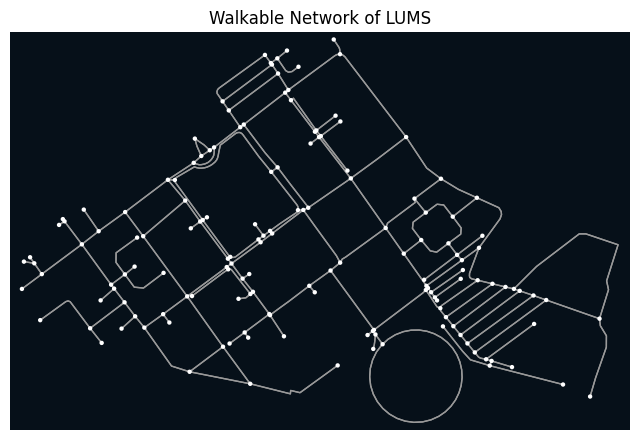

In [25]:
# Define the area of interest
place_name = "Lahore University of Management Sciences, Lahore, Pakistan"

# Download the street network for the area
print(f"Downloading the walkable network for '{place_name}'...")
graph = ox.graph_from_place(place_name, network_type='walk')
print("Map data downloaded successfully")

# Plot the street network to see what we're working with
fig, ax = ox.plot_graph(graph, node_size=10, edge_linewidth=1, show=False, close=False, bgcolor='#061019')
ax.set_title("Walkable Network of LUMS")
plt.show()

### Step 2: Implement the Heuristic Function

A* search requires a heuristic function, $h(n)$. For our map, we will implement the **Haversine formula** to calculate the straight-line distance between two points on a sphere (the Earth). This is an *admissible* heuristic because it never overestimates the true road distance.

**Your task is to translate this formula into Python code.**

**Variables:**
- $\phi$: Latitude
- $\lambda$: Longitude
- $r$: Earth's radius (6,371,000 meters)

**Formula Steps:**
2.  Calculate $c = 2 \cdot \text{atan2}\left(\sqrt{a}, \sqrt{1-a}\right)$
3.  Calculate distance $d = r \cdot c$

**Important:** Python's math functions (`math.sin`, `math.cos`) work with **radians**. You must convert the latitude and longitude values from degrees to radians first using `math.radians()`.

In [26]:
 def heuristic(node1_id, node2_id, graph):
    """
    Calculates the Haversine distance between two nodes.
    """
    '''
    Heuristic Function (Main Idea):
    So the main idea is that we are using the Haversine distance as the heuristic function to find the shortest path between the position and the goal as heuristic value.
    '''
    # Earth's radius in meters
    R = 6371000  

    # Get latitude and longitude for both nodes from the graph Math module is used to convert degrees to radians
    lat1 = graph.nodes[node1_id]['y']  # y is the latitude
    lon1 = graph.nodes[node1_id]['x']  # x is the longitude
    lat2 = graph.nodes[node2_id]['y']  # y is the latitude
    lon2 = graph.nodes[node2_id]['x']  # x is the longitude

    # Convert degrees to radians math
    phi1 = math.radians(lat1)  # phi1 is the latitude of the first node
    phi2 = math.radians(lat2)  # phi2 is the latitude of the second node
    delta_phi = math.radians(lat2 - lat1)  # delta_phi is the difference in latitude
    delta_lambda = math.radians(lon2 - lon1)  # delta_lambda is the difference in longitude

    # Haversine formula
    a = math.sin(delta_phi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(delta_lambda / 2) ** 2  # a is the haversine of the central angle
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))  # c is the central angle
    distance = R * c  # distance is the distance between the two nodes

    return distance  # return the distance between the two nodes


### Step 3: Implement the A* Search Algorithm

Now, implement the A* algorithm. Your goal is to find the path that minimizes the total estimated cost, $f(n)$, where:

$$f(n) = g(n) + h(n)$$

-   **$g(n)$**: The true road distance from the start to node $n$.
-   **$h(n)$**: Your Haversine heuristic from node $n$ to the goal.

You will use a **priority queue** to always expand the node with the lowest $f(n)$ value.

In [30]:
  def a_star_search(graph, start_node, goal_node):
    """
    Finds the shortest path between two nodes using the A* algorithm.
    """

    '''
    AStar Algorithm (Main Idea):
    So the main idea is that we are using the A* algorithm to find the shortest path between the start and the goal.We initialized a priority queue to store the positions to be visited and also intialized a set so mark 
    visited positions.The reason we are using set is that it is more efficient and also it only accpets unique values. We also intialized a dictionary to store the parent of each position so that we can reconstruct 
    the path from the goal to the start after we have reached the goal and the loop stops.We initialized a flag named goal_reached to check if the goal has been reached so that we can stop the loop.
    Once the loop Stops we start another loop in order to reconstruct the path from the goal to the start.we set the initial point as goal and keep on running till we reach the start and finally reverse
    the path to the goal.
    '''


    # Priority queue: (f_score, node)
    open_set = [] # Priority queue to store the positions to be visited
    heapq.heappush(open_set, (0, start_node)) # Add the start position to the open set.

    # For path reconstruction
    came_from = {} # Dictionary to store the parent of each position so that we can reconstruct the path from the goal to the start after we have reached the goal and the loop stops.

    # Cost from start to node
    g_score = {node: float('inf') for node in graph.nodes} # Dictionary to store the cost from the start to the current position.Setting to infinity as we don't know the cost from the start to the current position.
    g_score[start_node] = 0 # Add the cost from the start to the start position.

    # Estimated total cost from start to goal through node
    f_score = {node: float('inf') for node in graph.nodes} # Dictionary to store the estimated total cost from the start to the goal through the current position.Setting to infinity as we don't know the estimated total cost from the start to the goal through the current position.
    f_score[start_node] = heuristic(start_node, goal_node, graph) # Add the estimated total cost from the start to the goal through the start position.

    closed_set = set() # Set to store the positions that have been visited so that we do not visit them again and it avoid Duplicate entries.

    while open_set:
        current_f, current = heapq.heappop(open_set) # Pop the position with the lowest estimated total cost from the open set.
        if current == goal_node:
            # Reconstruct path
            path = [current] # Add the current position to the path.
            while current in came_from: # Running the loop until the current position is the start position.
                current = came_from[current] # Get the parent of the current position.
                path.append(current)
            path.reverse() # Reverse the path to the goal.
            return path

        closed_set.add(current) # Add the current position to the closed set.

        for neighbor in graph.neighbors(current):
            if neighbor in closed_set: # Check if the neighbor has been visited.
                continue
            # Edge cost
            edge_data = graph.get_edge_data(current, neighbor, default={}) # Get the edge data.
            # If multiple edges, take the first one
            if isinstance(edge_data, dict) and 0 in edge_data:
                edge_length = edge_data[0].get('length', 1) # Get the length of the edge.
            else:
                edge_length = edge_data.get('length', 1) # Get the length of the edge.
            tentative_g_score = g_score[current] + edge_length

            if tentative_g_score < g_score[neighbor]:
                came_from[neighbor] = current # Add the neighbor to the dictionary to check how we reached the neighbor from the start.
                g_score[neighbor] = tentative_g_score # Add the tentative cost to the dictionary.
                f_score[neighbor] = tentative_g_score + heuristic(neighbor, goal_node, graph) # Add the estimated total cost from the start to the goal through the neighbor.
                heapq.heappush(open_set, (f_score[neighbor], neighbor)) # Add the neighbor to the open set.

    return None # Return None if no path is found.  


### Step 4: Find and Visualize the Route from SDSB to SSE

This final cell will use your functions to find the shortest path and display it on a static map.

In [28]:
# Define the coordinates for the two buildings (DO NOT CHANGE THE VALUES OF THE COORDINATES)
sdsb_location = (31.4687, 74.4095) # Suleman Dawood School of Business
sse_location = (31.4718, 74.4111)  # Syed Babar Ali School of Science and Engineering

# Find the closest nodes in the graph to these coordinates 
sdsb_node = ox.distance.nearest_nodes(graph, sdsb_location[1], sdsb_location[0])
sse_node = ox.distance.nearest_nodes(graph, sse_location[1], sse_location[0])

print(f"Nearest node to SDSB: {sdsb_node}")
print(f"Nearest node to SSE: {sse_node}")

# --- TODO: CALL YOUR A* SEARCH ALGORITHM HERE ---
path = a_star_search(graph, sdsb_node, sse_node)

Nearest node to SDSB: 11337034499
Nearest node to SSE: 810005319



 Number of intersections in path: 12
Total route distance: 479.92 meters


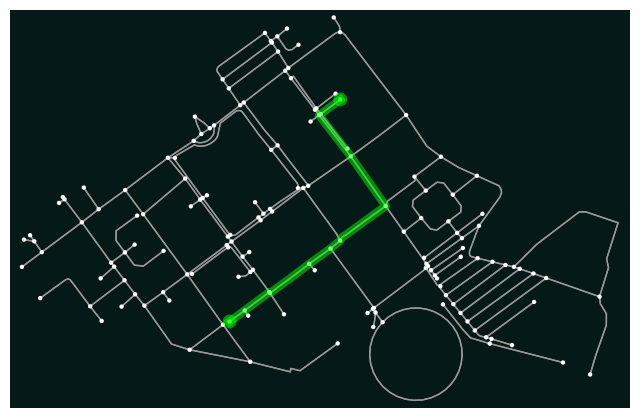

In [29]:
# Visualize the route using a static matplotlib plot (DO NOT CHANGE THIS CELL)
if path:
    print(f"\n Number of intersections in path: {len(path)}")
    total_distance = nx.path_weight(graph, path, weight='length')
    print(f"Total route distance: {total_distance:.2f} meters")

    fig, ax = ox.plot_graph_route(
        graph,
        path,
        route_color='lime',
        route_linewidth=6,
        node_size=10,
        bgcolor='#061919'
    )
    ax.set_title("Shortest Path from SDSB to SSE")

else:
    print("\nNo path found between the specified points.")

### Step 5: Theoretical Analysis

Based on the A* algorithm you just implemented and the results you observed, answer the following questions.

#### Question 1: The Role of the Heuristic

Our A* implementation depends on the Haversine distance heuristic.

a)  What does it mean for a heuristic to be **admissible**? Is our Haversine distance heuristic admissible? Why is this property crucial for A* to find the *shortest* path?

b)  What do you think would happen if our heuristic was **inadmissible** (i.e., it sometimes *overestimated* the distance to the goal)? Would A* still find a path? Would it be guaranteed to be the shortest one?

a) A heuristic is admissible if it never overestimates the true minimum cost to reach the goal node. a heuristic is just an estimated cost from a node to goal.Yes Haversine distance is admissible here
   as it calculates the straight line distance between two points on earth. In real world it not possible to reach goal by walking in a straight line so, it will be longer then then the straight line distance.As we know that heuristic must be admissible for the A* to find the shortest path. In a case where heuristic is not admissible you can that it overestimates then A* might ignore the optimal path think it as an expensive path.If heuristic is admissible then it will reach the goal in the first try when it reached a goal.

b) If our heuristic is inadmissible which mean if it overestimates it will still find the path as long a path exists in the graph. However, it is not guaranteed that it will be the shortest path. Because due to overestimation of the cost can cause A* to ignore a certain path moreover it can delay exploring the optimal path. So as a result it may go for other path which may be longer and not optimal